# NPS Preditivo — Análise Exploratória dos Dados (EDA)

**Tech Challenge Fase 1 — PosTech FIAP**  
**Área:** Ciência de Dados com ênfase em Inteligência Artificial

---

## Contexto

Uma empresa de e-commerce enfrenta alta variabilidade no **Net Promoter Score (NPS)** entre seus clientes.  
O NPS hoje só é coletado *após* o encerramento da jornada de compra, o que impede qualquer ação preventiva.

## Objetivo desta análise

Explorar os dados operacionais disponíveis — logística, atendimento e perfil do cliente — para responder:

> **Quais fatores realmente influenciam a satisfação do cliente e onde estão os pontos de ruptura na experiência?**

Esta análise serve de base para as recomendações ao negócio e para a construção do modelo preditivo (notebook `02_modelo.ipynb`).

---

## Estrutura do notebook

1. Configuração do ambiente
2. Carregamento e visão geral dos dados
3. Distribuição do NPS *(próxima seção)*
4. Análise por fator logístico *(próxima seção)*
5. Análise por fator de atendimento *(próxima seção)*
6. Perfil do cliente *(próxima seção)*
7. Correlações e pontos de ruptura *(próxima seção)*
8. Conclusões e recomendações *(próxima seção)*

## 1. Configuração do ambiente

Importamos as bibliotecas que serão usadas ao longo de toda a análise.  
É boa prática centralizar todas as importações na primeira célula de código para facilitar a leitura e a reprodução do notebook.

In [2]:
# pandas: biblioteca principal para manipulação de dados em formato tabular (DataFrames)
import pandas as pd

# numpy: suporte a operações matemáticas e vetorizadas sobre arrays
import numpy as np

# matplotlib: biblioteca base para criação de gráficos em Python
import matplotlib.pyplot as plt

# seaborn: biblioteca de visualização construída sobre o matplotlib,
# com estilos mais elegantes e funções de alto nível para análise estatística
import seaborn as sns

# warnings: usamos para suprimir avisos não críticos que poluem o output
import warnings
warnings.filterwarnings('ignore')

# Define o estilo visual padrão dos gráficos para toda a sessão
# 'whitegrid' adiciona grade branca ao fundo, facilitando a leitura dos valores
sns.set_style('whitegrid')

# Define o tamanho padrão de todas as figuras (largura x altura em polegadas)
# Evita ter que redefinir em cada gráfico
plt.rcParams['figure.figsize'] = (12, 5)

# Define a paleta de cores padrão do seaborn
# 'Set2' oferece cores distintas e adequadas para variáveis categóricas
sns.set_palette('Set2')

print('Bibliotecas carregadas com sucesso.')

Bibliotecas carregadas com sucesso.


## 2. Carregamento e visão geral dos dados

Antes de qualquer análise, precisamos entender **o que temos**:  
quantos registros, quais variáveis, que tipos de dados e se há valores ausentes.  

Essa etapa é equivalente a abrir uma planilha pela primeira vez e dar uma olhada geral antes de começar a trabalhar.

In [3]:
# Carrega o arquivo CSV em um DataFrame pandas
# O caminho '../data/' sobe um nível (saindo de notebooks/) e entra em data/
# Isso funciona porque o notebook está em notebooks/ e o CSV está em data/
df = pd.read_csv('../data/desafio_nps_fase_1.csv')

# Exibe as dimensões: (número de linhas, número de colunas)
# Importante para saber o tamanho da base antes de qualquer operação
print(f'Dimensões do dataset: {df.shape[0]:,} linhas x {df.shape[1]} colunas')

Dimensões do dataset: 2,500 linhas x 19 colunas


In [4]:
# Exibe as primeiras 5 linhas do dataset
# Permite uma primeira inspeção visual das colunas e dos valores reais
df.head()

,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


In [5]:
# Exibe o tipo de dado de cada coluna (int64, float64, object)
# Essencial para identificar colunas categóricas (object) vs numéricas (int/float)
# e planejar as transformações necessárias antes da modelagem
print('Tipos de dados por coluna:')
print(df.dtypes)

Tipos de dados por coluna:
customer_id                    int64
customer_age                   int64
customer_region                  str
customer_tenure_months         int64
order_id                       int64
order_value                  float64
items_quantity                 int64
discount_value               float64
payment_installments           int64
delivery_time_days             int64
delivery_delay_days            int64
freight_value                float64
delivery_attempts              int64
customer_service_contacts      int64
resolution_time_days           int64
nps_score                    float64
repeat_purchase_30d            int64
complaints_count               int64
csat_internal_score          float64
dtype: object


In [6]:
# Conta os valores nulos (NaN) em cada coluna
# Valores nulos precisam ser tratados antes da modelagem;
# saber onde estão define a estratégia: imputação pela média, moda ou remoção da linha
nulos = df.isnull().sum()

# Filtra e exibe apenas colunas com pelo menos 1 valor nulo
# Se o resultado estiver vazio, o dataset está completo — nenhuma ação necessária
print('Colunas com valores nulos:')
if nulos.sum() > 0:
    print(nulos[nulos > 0])
else:
    print('Nenhum valor nulo encontrado. Dataset completo.')

Colunas com valores nulos:
Nenhum valor nulo encontrado. Dataset completo.


In [7]:
# Gera estatísticas descritivas para todas as colunas numéricas:
# count (total de registros), mean (média), std (desvio padrão),
# min, 25%, 50% (mediana), 75% e max
# Permite identificar rapidamente:
#   - outliers: quando min ou max está muito distante dos quartis
#   - assimetria: quando mean e mediana (50%) são muito diferentes
#   - escalas diferentes entre variáveis (importante para normalização no modelo)
df.describe().round(2)

,customer_id,customer_age,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
count,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00
mean,1250.50,43.40,61.32,51250.50,434.26,3.47,29.75,6.00,8.02,2.19,38.22,2.01,1.52,5.49,4.38,0.09,4.15,2.94
std,721.83,14.89,34.48,721.83,289.77,1.69,29.23,3.16,3.77,1.45,12.08,0.82,1.23,3.46,2.51,0.28,1.78,2.38
min,1.00,18.00,1.00,50001.00,7.76,1.00,0.02,1.00,2.00,0.00,2.62,1.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,625.75,31.00,31.00,50625.75,220.24,2.00,8.88,3.00,5.00,1.00,29.93,1.00,1.00,2.00,2.60,0.00,3.00,0.70
50%,1250.50,43.00,62.00,51250.50,375.52,3.00,20.94,6.00,8.00,2.00,38.50,2.00,1.00,6.00,4.40,0.00,4.00,2.80
75%,1875.25,56.00,91.00,51875.25,577.29,5.00,40.83,9.00,11.00,3.00,46.27,3.00,2.00,8.00,6.10,0.00,5.00,4.80
max,2500.00,69.00,119.00,52500.00,1983.81,6.00,230.33,11.00,14.00,8.00,76.13,3.00,7.00,11.00,10.00,1.00,11.00,10.00


In [8]:
# Conta os valores únicos por coluna para entender a cardinalidade de cada variável
# Cardinalidade baixa (2-5 valores) sugere variável categórica ou binária
# Cardinalidade alta (centenas ou mais) sugere variável contínua ou identificador
print('Valores únicos por coluna:')
for col in df.columns:
    if df[col].dtype == 'object':
        # Para colunas de texto, exibe também quais são os valores possíveis
        # útil para confirmar categorias como regiões, status, etc.
        print(f'  {col}: {df[col].nunique()} únicos -> {df[col].unique().tolist()}')
    else:
        # Para colunas numéricas, exibe apenas a contagem de únicos
        print(f'  {col}: {df[col].nunique()} únicos')

Valores únicos por coluna:
  customer_id: 2500 únicos
  customer_age: 52 únicos
  customer_region: 5 únicos
  customer_tenure_months: 119 únicos
  order_id: 2500 únicos
  order_value: 2457 únicos
  items_quantity: 6 únicos
  discount_value: 2050 únicos
  payment_installments: 11 únicos
  delivery_time_days: 13 únicos
  delivery_delay_days: 9 únicos
  freight_value: 1897 únicos
  delivery_attempts: 3 únicos
  customer_service_contacts: 8 únicos
  resolution_time_days: 12 únicos
  nps_score: 101 únicos
  repeat_purchase_30d: 2 únicos
  complaints_count: 12 únicos
  csat_internal_score: 98 únicos


## Seção 2: Análise da variável alvo (nps_score)

O primeiro passo de qualquer projeto de Machine Learning é entender profundamente a **variável alvo** — aquela que o modelo vai aprender a prever.

Neste case, a variável alvo é o `nps_score`: a nota de satisfação do cliente coletada após a compra.

### Por que analisar a variável alvo antes de tudo?

- Para saber se o dataset está **balanceado** (proporções semelhantes entre classes) ou **desbalanceado** (uma classe domina as outras) — isso impacta diretamente a escolha e avaliação do modelo.
- Para entender **como o negócio classifica** essa nota em categorias acionáveis.
- Para calcular o **NPS real da empresa** e ter o diagnóstico de ponto de partida.

### Classificação oficial do NPS

| Nota | Categoria | Comportamento esperado |
|------|-----------|------------------------|
| 9 – 10 | **Promotor** | Recomenda ativamente, tende a recomprar |
| 7 – 8 | **Neutro** | Indiferente, não recomenda nem critica |
| 0 – 6 | **Detrator** | Insatisfeito, pode gerar críticas públicas |

### Fórmula do NPS real

```
NPS = % Promotores − % Detratores
```

> Os **neutros são ignorados** no cálculo — eles não movem o ponteiro da marca nem positivamente nem negativamente.

In [9]:
# Função que traduz a nota numérica (0-10) para a categoria de negócio
# Seguindo a metodologia oficial criada por Fred Reichheld (Harvard Business Review, 2003)
def classificar_nps(score):
    if score >= 9:
        return 'Promotor'
    elif score >= 7:
        return 'Neutro'
    else:
        return 'Detrator'

# Aplica a função em cada valor da coluna nps_score e cria uma nova coluna
# Esta nova coluna 'nps_categoria' será a variável alvo (target) do modelo de classificação
df['nps_categoria'] = df['nps_score'].apply(classificar_nps)

# --- Cálculo do NPS real da empresa ---

# Total de clientes na base
total = len(df)

# Conta clientes por categoria usando a coluna recém-criada
contagem = df['nps_categoria'].value_counts()

# .get(cat, 0) garante que não haverá erro caso alguma categoria esteja ausente
n_promotores = contagem.get('Promotor', 0)
n_neutros    = contagem.get('Neutro', 0)
n_detratores = contagem.get('Detrator', 0)

# Converte contagens em percentuais (0 a 100)
pct_promotores = n_promotores / total * 100
pct_neutros    = n_neutros    / total * 100
pct_detratores = n_detratores / total * 100

# Aplica a fórmula oficial: NPS = % Promotores - % Detratores
# Os neutros NÃO entram no cálculo — apenas diluem o denominador (total)
nps_empresa = pct_promotores - pct_detratores

# Exibe o resultado formatado
print('=' * 45)
print(f'  Promotores : {n_promotores:>5}  ({pct_promotores:.1f}%)')
print(f'  Neutros    : {n_neutros:>5}  ({pct_neutros:.1f}%)')
print(f'  Detratores : {n_detratores:>5}  ({pct_detratores:.1f}%)')
print('=' * 45)
print(f'  NPS da empresa : {nps_empresa:.1f}')
print('=' * 45)
print()
print('Referência de mercado:')
print('  Acima de  75 → Excelente')
print('  50 a  75     → Muito bom')
print('   0 a  50     → Bom')
print('  Negativo     → Crítico — clientes insatisfeitos superam os satisfeitos')

  Promotores :   110  (4.4%)
  Neutros    :   281  (11.2%)
  Detratores :  2109  (84.4%)
  NPS da empresa : -80.0

Referência de mercado:
  Acima de  75 → Excelente
  50 a  75     → Muito bom
   0 a  50     → Bom
  Negativo     → Crítico — clientes insatisfeitos superam os satisfeitos


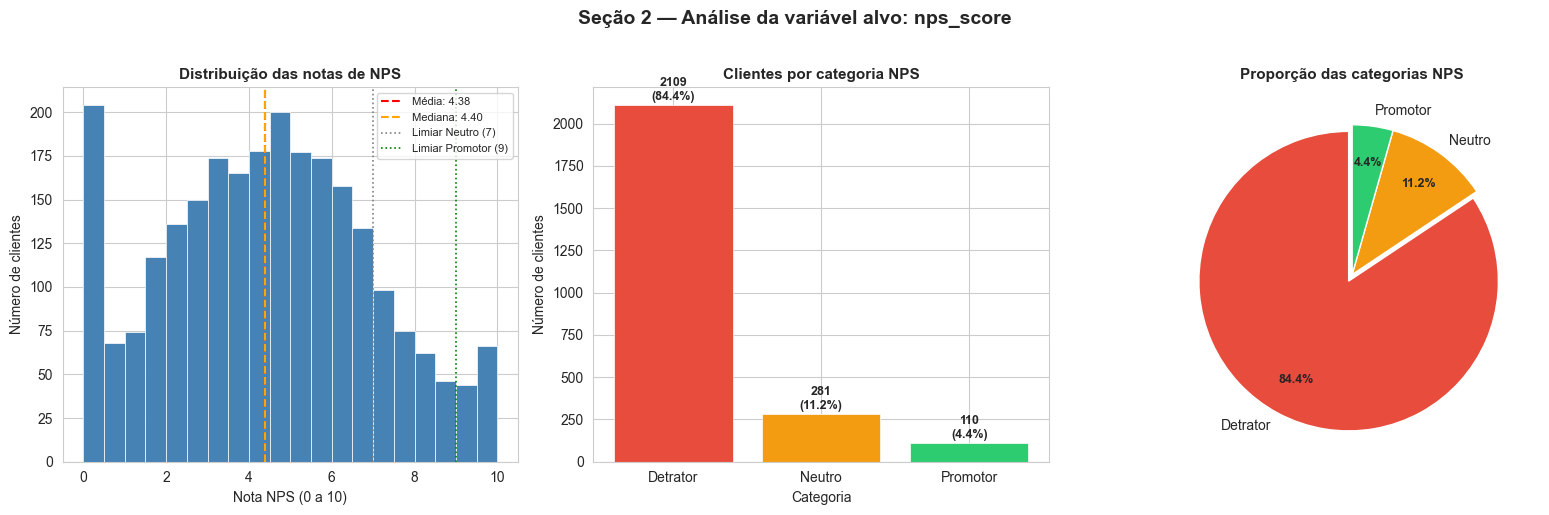

In [10]:
# Cria um painel com 3 gráficos para mostrar a variável alvo sob três ângulos diferentes
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5))

# ---------------------------------------------------------------
# Gráfico 1 — Histograma da nota bruta
# Mostra COMO as notas se distribuem ao longo da escala 0-10
# ---------------------------------------------------------------
ax1.hist(df['nps_score'], bins=20, color='steelblue', edgecolor='white', linewidth=0.5)

# Linha da média — permite ver se está na zona de detrator, neutro ou promotor
ax1.axvline(df['nps_score'].mean(), color='red', linestyle='--', linewidth=1.5,
            label=f'Média: {df["nps_score"].mean():.2f}')

# Linha da mediana — quando muito diferente da média, indica assimetria na distribuição
ax1.axvline(df['nps_score'].median(), color='orange', linestyle='--', linewidth=1.5,
            label=f'Mediana: {df["nps_score"].median():.2f}')

# Limiares de classificação: onde começa a zona Neutro (7) e Promotor (9)
ax1.axvline(7, color='gray',  linestyle=':', linewidth=1.2, label='Limiar Neutro (7)')
ax1.axvline(9, color='green', linestyle=':', linewidth=1.2, label='Limiar Promotor (9)')

ax1.set_title('Distribuição das notas de NPS', fontsize=11, fontweight='bold')
ax1.set_xlabel('Nota NPS (0 a 10)')
ax1.set_ylabel('Número de clientes')
ax1.legend(fontsize=8)

# ---------------------------------------------------------------
# Gráfico 2 — Barras com contagem por categoria
# Mostra o RESULTADO da classificação de forma direta e comparável
# ---------------------------------------------------------------
ordem  = ['Detrator', 'Neutro', 'Promotor']
cores  = ['#e74c3c', '#f39c12', '#2ecc71']   # vermelho, amarelo, verde
valores = [contagem.get(cat, 0) for cat in ordem]

barras = ax2.bar(ordem, valores, color=cores, edgecolor='white', linewidth=0.5)

# Rótulo com contagem absoluta e percentual acima de cada barra
for barra, val in zip(barras, valores):
    pct = val / total * 100
    # ha='center' centraliza o texto horizontalmente sobre a barra
    ax2.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 15,
        f'{val}\n({pct:.1f}%)',
        ha='center', va='bottom', fontsize=9, fontweight='bold'
    )

ax2.set_title('Clientes por categoria NPS', fontsize=11, fontweight='bold')
ax2.set_xlabel('Categoria')
ax2.set_ylabel('Número de clientes')

# ---------------------------------------------------------------
# Gráfico 3 — Pizza com proporções
# Melhor para comunicar a DOMINÂNCIA de uma categoria sobre as outras
# O gráfico de pizza torna imediato o impacto visual de 84% de detratores
# ---------------------------------------------------------------
# explode "puxa" a fatia de Detrator para fora, destacando o problema principal
explode = (0.05, 0, 0)   # (Detrator, Neutro, Promotor)

wedges, texts, autotexts = ax3.pie(
    valores,
    labels=ordem,
    colors=cores,
    explode=explode,
    autopct='%1.1f%%',        # mostra o percentual dentro de cada fatia
    startangle=90,            # começa pelo topo (12h) para melhor visualização
    pctdistance=0.75          # posição do percentual dentro da fatia
)

# Aumenta o tamanho dos textos para melhor leitura
for text in autotexts:
    text.set_fontsize(9)
    text.set_fontweight('bold')

ax3.set_title('Proporção das categorias NPS', fontsize=11, fontweight='bold')

# Título geral do painel
fig.suptitle('Seção 2 — Análise da variável alvo: nps_score',
             fontsize=14, fontweight='bold', y=1.02)

plt.tight_layout()

# Salva em reports/ para uso nos slides de apresentação
plt.savefig('../reports/01_analise_variavel_alvo.png', dpi=150, bbox_inches='tight')
plt.show()

## Seção 3: Impacto do atraso na entrega no NPS

Das variáveis operacionais disponíveis, `delivery_delay_days` (dias de atraso em relação ao prazo prometido) é a que apresenta a **correlação mais forte com o NPS** (−0,60).

Nesta seção vamos responder:

- À medida que o atraso aumenta, o NPS cai de forma linear ou existe um **ponto de ruptura** — um momento específico em que a insatisfação dispara?
- Qual é a intensidade dessa relação (correlação)?
- O que isso significa na prática para o time de operações?

In [11]:
# Calcula o NPS médio e a quantidade de clientes para cada valor de atraso
# groupby agrupa todas as linhas com o mesmo número de dias de atraso
# agg aplica duas funções simultâneas: média do nps_score e contagem de registros
nps_por_atraso = (
    df.groupby('delivery_delay_days')['nps_score']
    .agg(nps_medio='mean', total_clientes='count')
    .round(2)
    .reset_index()  # transforma o índice de volta em coluna para facilitar o plot
)

# Calcula a correlação de Pearson entre atraso e NPS
# Pearson mede relação LINEAR: varia de -1 (inversamente linear) a +1 (diretamente linear)
# Um valor de -0,6 indica correlação negativa moderada-forte
correlacao = df['delivery_delay_days'].corr(df['nps_score'])

print('NPS médio por dias de atraso na entrega:')
print(f'{"Atraso (dias)":<18} {"NPS médio":<14} {"Clientes":<10}')
print('-' * 42)
for _, linha in nps_por_atraso.iterrows():
    # Marca visualmente o ponto de ruptura: onde NPS cai abaixo de 3.5
    # Após 3 dias de atraso, o cliente entra em zona de dano reputacional grave
    alerta = ' <-- ruptura' if linha['nps_medio'] < 3.5 and linha['delivery_delay_days'] == 3 else ''
    print(f"  {int(linha['delivery_delay_days']):<16} {linha['nps_medio']:<14} {int(linha['total_clientes']):<10}{alerta}")

print(f'\nCorrelação de Pearson (atraso x NPS): {correlacao:.3f}')
print('Interpretação: correlação negativa forte — quanto mais dias de atraso, menor o NPS')

NPS médio por dias de atraso na entrega:
Atraso (dias)      NPS médio      Clientes  
------------------------------------------
  0                6.86           277       
  1                5.55           615       
  2                4.58           646       
  3                3.44           525        <-- ruptura
  4                2.44           270       
  5                1.48           116       
  6                1.1            34        
  7                0.29           14        
  8                0.0            3         

Correlação de Pearson (atraso x NPS): -0.597
Interpretação: correlação negativa forte — quanto mais dias de atraso, menor o NPS


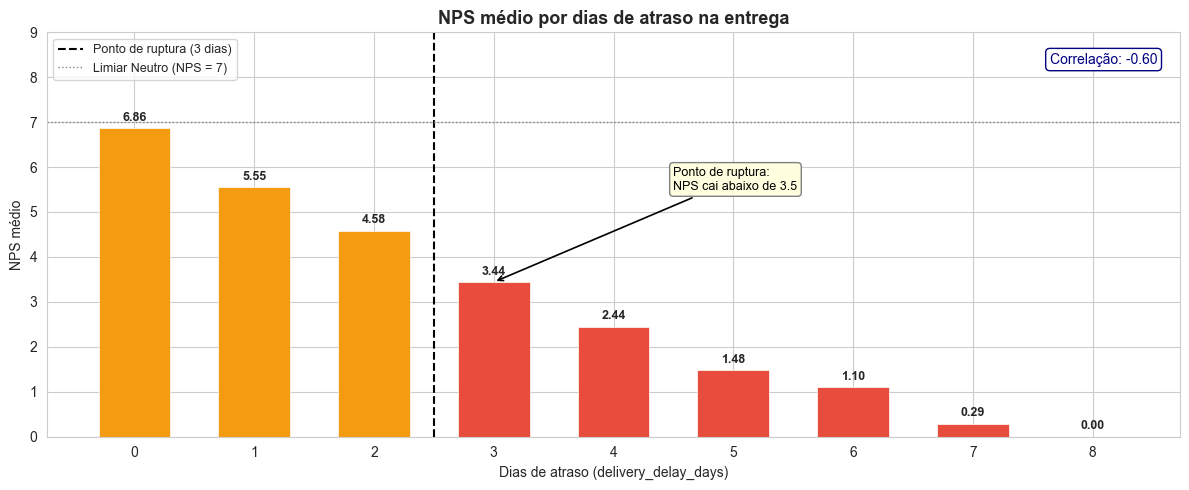

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))

dias   = nps_por_atraso['delivery_delay_days'].astype(int)
medias = nps_por_atraso['nps_medio']

# Define a cor de cada barra com base no valor de NPS médio:
# verde (>= 7) = zona aceitável | amarelo (>= 4) = atenção | vermelho (< 4) = crítico
# Essa codificação de cores torna o gráfico autoexplicativo para um público não técnico
cores_barras = [
    '#2ecc71' if v >= 7 else ('#f39c12' if v >= 4 else '#e74c3c')
    for v in medias
]

barras = ax.bar(dias, medias, color=cores_barras, edgecolor='white', linewidth=0.5, width=0.6)

# Rótulo com o NPS médio acima de cada barra
for barra, val in zip(barras, medias):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.1,
        f'{val:.2f}',
        ha='center', va='bottom', fontsize=9, fontweight='bold'
    )

# --- Destaque do ponto de ruptura ---
# O ponto de ruptura está em 3 dias de atraso: NPS cai abaixo de 3.5 pela primeira vez,
# sinalizando que o cliente passou do incômodo para a insatisfação grave
ponto_ruptura = 3
ax.axvline(
    x=ponto_ruptura - 0.5,       # linha logo antes da barra de 3 dias
    color='black', linestyle='--', linewidth=1.5, label='Ponto de ruptura (3 dias)'
)

# Anotação de texto diretamente no gráfico para guiar o leitor
ax.annotate(
    'Ponto de ruptura:\nNPS cai abaixo de 3.5',
    xy=(ponto_ruptura, medias.iloc[ponto_ruptura]),      # ponta da seta: topo da barra de 3 dias
    xytext=(ponto_ruptura + 1.5, 5.5),                   # corpo do texto: deslocado para não sobrepor
    fontsize=9,
    color='black',
    arrowprops=dict(arrowstyle='->', color='black', lw=1.2),  # seta apontando para a barra
    bbox=dict(boxstyle='round,pad=0.3', fc='lightyellow', ec='gray')  # caixa ao redor do texto
)

# Linha horizontal tracejada marcando o limiar de NPS "Neutro" (7.0)
# Serve de referência visual: nenhuma barra chega a essa linha
ax.axhline(7, color='gray', linestyle=':', linewidth=1, label='Limiar Neutro (NPS = 7)')

# Exibe a correlação diretamente no gráfico para o leitor técnico
ax.text(
    0.98, 0.95,
    f'Correlação: {correlacao:.2f}',
    transform=ax.transAxes,   # coordenadas relativas ao eixo (0=esquerda, 1=direita)
    ha='right', va='top',
    fontsize=10, color='navy',
    bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='navy')
)

ax.set_title('NPS médio por dias de atraso na entrega', fontsize=13, fontweight='bold')
ax.set_xlabel('Dias de atraso (delivery_delay_days)')
ax.set_ylabel('NPS médio')
ax.set_xticks(dias)   # garante que todos os valores de atraso apareçam no eixo X
ax.set_ylim(0, 9)
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('../reports/03_nps_por_atraso.png', dpi=150, bbox_inches='tight')
plt.show()

### Interpretação para o negócio

**O que o gráfico diz em linguagem simples:**

Quando um pedido chega no prazo, a nota do cliente é **6,86** — já baixa, mas ainda gerenciável.
A cada dia a mais de atraso, essa nota cai quase **1 ponto inteiro**.

O **ponto crítico está nos 3 dias de atraso**: a partir daí, a nota cai abaixo de **3,5** e o cliente entra em modo de insatisfação grave — aquele em que ele fala mal da empresa para amigos e familiares, e considera nunca mais comprar.

Com **5 dias de atraso**, a nota chega a **1,48**. Com 8 dias, vai a **zero**.

---

**O que o time de operações pode fazer com essa informação:**

| Situação | Ação recomendada |
|----------|-----------------|
| Pedido com 1–2 dias de atraso | Comunicação proativa ao cliente com nova data estimada |
| Pedido chegando ao 3º dia de atraso | Acionar protocolo de recuperação: contato direto, compensação (cupom, frete grátis) |
| Pedido com 5+ dias de atraso | Escalonamento imediato — risco de detrator público (reclamação em redes sociais) |

> **Mensagem principal:** não é necessário zerar o atraso para melhorar o NPS. Reduzir de 5 dias para 2 dias já representa uma melhora de mais de **3 pontos** na nota média do cliente — o equivalente a sair da zona vermelha para a amarela.

## Seção 5: Variáveis sem impacto relevante no NPS

Tão importante quanto saber **o que impacta** o NPS é saber **o que não impacta**.

Identificar variáveis sem relação com a satisfação do cliente evita que a empresa invista tempo e dinheiro em ações que não vão mover o ponteiro — como segmentar campanhas por faixa etária ou priorizar pedidos de maior valor acreditando que isso aumenta o NPS.

Nesta seção usamos o **heatmap de correlação** para ter uma visão panorâmica de todas as relações numéricas com `nps_score` de uma vez só.

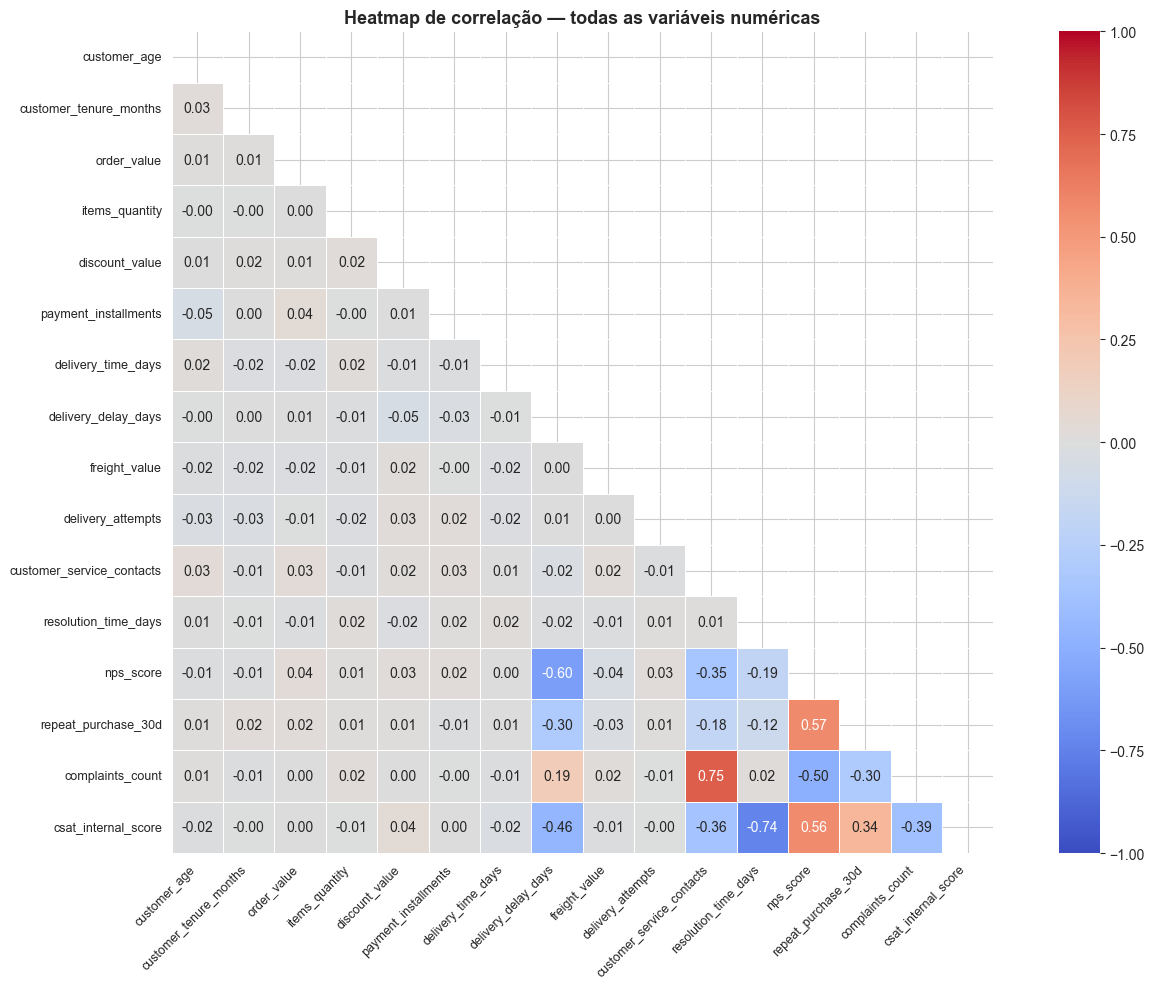

In [13]:
# Remove colunas de identificação pura — customer_id e order_id são apenas chaves
# e não carregam nenhuma informação preditiva sobre satisfação
colunas_excluir = ['customer_id', 'order_id']
df_num = df.drop(columns=colunas_excluir).select_dtypes(include='number')

# Calcula a matriz de correlação de Pearson entre todas as variáveis numéricas
# O resultado é uma tabela N×N onde cada célula indica a correlação entre dois pares
matriz_corr = df_num.corr()

# Cria uma máscara booleana para o triângulo superior da matriz
# O heatmap é simétrico (corr(A,B) == corr(B,A)), então exibir metade evita redundância
mascara = np.triu(np.ones_like(matriz_corr, dtype=bool))

fig, ax = plt.subplots(figsize=(14, 10))

# Heatmap de correlação com paleta divergente:
# azul escuro = correlação negativa forte | branco = sem correlação | vermelho = positiva forte
# center=0 garante que o branco fique exatamente no zero, sem distorção de escala
sns.heatmap(
    matriz_corr,
    mask=mascara,          # oculta o triângulo superior (redundante)
    annot=True,            # exibe o valor numérico dentro de cada célula
    fmt='.2f',             # formata com 2 casas decimais
    cmap='coolwarm',       # paleta divergente: azul (negativo) → branco (zero) → vermelho (positivo)
    center=0,
    vmin=-1, vmax=1,       # fixa a escala de cores entre -1 e +1
    linewidths=0.5,        # adiciona linhas finas entre as células para melhor leitura
    square=True,           # mantém as células quadradas
    ax=ax
)

ax.set_title('Heatmap de correlação — todas as variáveis numéricas', fontsize=13, fontweight='bold')

# Rotaciona os rótulos do eixo X para não sobrepor
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)

plt.tight_layout()
plt.savefig('../reports/04_heatmap_correlacao.png', dpi=150, bbox_inches='tight')
plt.show()

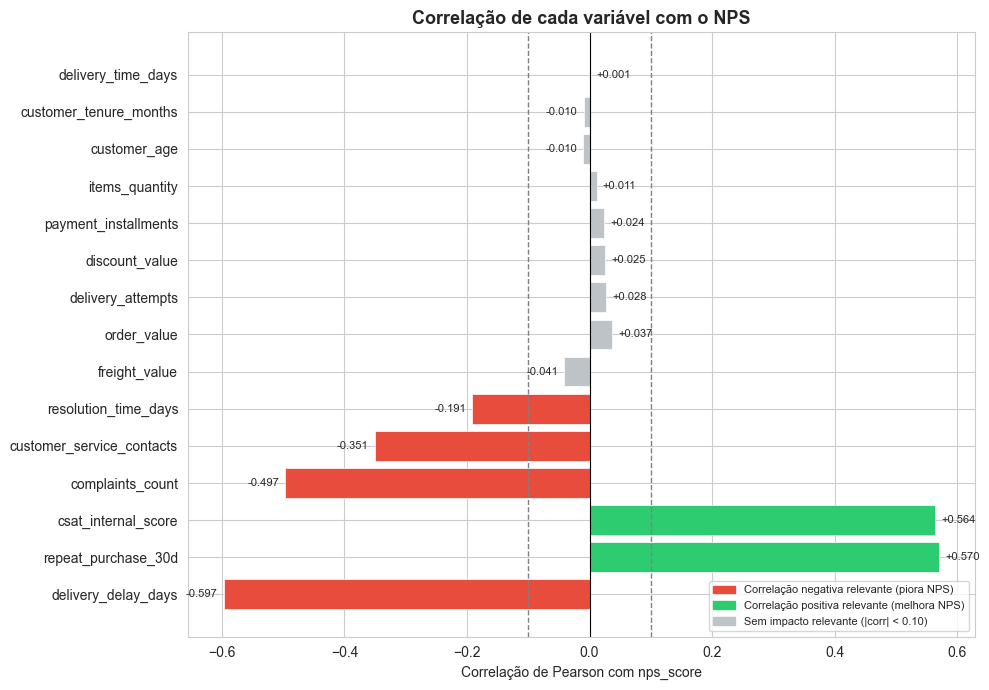

Variáveis sem impacto relevante no NPS (|correlação| < 0.10):
  freight_value: -0.041
  order_value: +0.037
  delivery_attempts: +0.028
  discount_value: +0.025
  payment_installments: +0.024
  items_quantity: +0.011
  customer_age: -0.010
  customer_tenure_months: -0.010
  delivery_time_days: +0.001


In [14]:
# Extrai apenas a coluna de correlação com nps_score e ordena do maior para o menor
# Isso transforma o heatmap (visão geral) em um ranking objetivo de influência
corr_com_nps = (
    matriz_corr['nps_score']
    .drop('nps_score')             # remove a autocorrelação (nps_score com ele mesmo = 1.0)
    .sort_values(key=abs, ascending=False)  # ordena pelo valor absoluto — negativos fortes sobem
)

# Define o limiar a partir do qual consideramos correlação "relevante"
# Correlações entre -0.10 e +0.10 são estatisticamente fracas e sem valor prático
LIMIAR_RELEVANTE = 0.10

fig, ax = plt.subplots(figsize=(10, 7))

# Cor de cada barra: vermelho para correlação negativa, verde para positiva, cinza para irrelevante
cores_ranking = []
for val in corr_com_nps:
    if abs(val) < LIMIAR_RELEVANTE:
        cores_ranking.append('#bdc3c7')   # cinza: sem impacto relevante
    elif val < 0:
        cores_ranking.append('#e74c3c')   # vermelho: correlação negativa (piora o NPS)
    else:
        cores_ranking.append('#2ecc71')   # verde: correlação positiva (melhora o NPS)

barras = ax.barh(corr_com_nps.index, corr_com_nps.values,
                 color=cores_ranking, edgecolor='white', linewidth=0.5)

# Rótulo com o valor exato de correlação ao lado de cada barra
for barra, val in zip(barras, corr_com_nps.values):
    offset = 0.01 if val >= 0 else -0.01
    ha     = 'left' if val >= 0 else 'right'
    ax.text(val + offset, barra.get_y() + barra.get_height() / 2,
            f'{val:+.3f}', va='center', ha=ha, fontsize=8)

# Linhas verticais marcando o limiar de relevância
# O que está entre as duas linhas cinzas é considerado sem impacto prático
ax.axvline( LIMIAR_RELEVANTE, color='gray', linestyle='--', linewidth=1,
            label=f'Limiar de relevância (±{LIMIAR_RELEVANTE})')
ax.axvline(-LIMIAR_RELEVANTE, color='gray', linestyle='--', linewidth=1)

# Anotação destacando as variáveis irrelevantes
variaveis_irrelevantes = corr_com_nps[abs(corr_com_nps) < LIMIAR_RELEVANTE].index.tolist()
ax.set_title('Correlação de cada variável com o NPS', fontsize=13, fontweight='bold')
ax.set_xlabel('Correlação de Pearson com nps_score')
ax.axvline(0, color='black', linewidth=0.8)   # linha central de referência no zero

# Legenda manual explicando o código de cores
from matplotlib.patches import Patch
legenda = [
    Patch(color='#e74c3c', label='Correlação negativa relevante (piora NPS)'),
    Patch(color='#2ecc71', label='Correlação positiva relevante (melhora NPS)'),
    Patch(color='#bdc3c7', label='Sem impacto relevante (|corr| < 0.10)'),
]
ax.legend(handles=legenda, fontsize=8, loc='lower right')

plt.tight_layout()
plt.savefig('../reports/05_ranking_correlacao_nps.png', dpi=150, bbox_inches='tight')
plt.show()

print('Variáveis sem impacto relevante no NPS (|correlação| < 0.10):')
for v in variaveis_irrelevantes:
    print(f'  {v}: {corr_com_nps[v]:+.3f}')

### Por que `delivery_time_days` não importa, mas `delivery_delay_days` sim?

Este é um dos achados mais contraintuitivos e valiosos da análise.

**`delivery_time_days`** mede quantos dias o pedido levou para chegar desde a compra.  
**`delivery_delay_days`** mede quantos dias a entrega atrasou em relação ao **prazo prometido**.

A diferença é de **expectativa vs. realidade**.

---

Um pedido que leva **14 dias** para chegar, mas foi prometido para **14 dias**, tem `delivery_delay_days = 0`. O cliente recebeu exatamente o que esperava — não há frustração.

Um pedido que leva **4 dias** para chegar, mas foi prometido para **2 dias**, tem `delivery_delay_days = 2`. O cliente esperava receber ontem — há frustração, mesmo que a entrega tenha sido rápida no absoluto.

A correlação dos dados confirma isso com precisão:

| Variável | Correlação com NPS |
|---|---|
| `delivery_time_days` (tempo absoluto) | **+0.001** — praticamente zero |
| `delivery_delay_days` (dias de atraso) | **−0.597** — correlação forte |

---

**O que o cliente compra não é velocidade — é previsibilidade.**

Quando a loja promete 5 dias e entrega em 5 dias, o cliente está satisfeito.  
Quando promete 2 dias e entrega em 4, ele está frustrado — mesmo que 4 dias seja objetivamente rápido.

O problema não está na logística em si. Está no **gap entre o que é prometido e o que é entregue**.

### Outras variáveis sem impacto relevante

| Variável | Correlação | Interpretação |
|---|---|---|
| `customer_age` | ≈ 0 | Clientes jovens e velhos têm NPS semelhante — segmentar por idade não ajuda |
| `order_value` | ≈ +0.04 | Comprar mais caro não gera mais satisfação — o NPS não é sobre preço |
| `delivery_time_days` | ≈ 0 | Explicado acima: tempo absoluto não importa, só o atraso em relação ao prometido |
| `freight_value` | ≈ −0.04 | Frete mais caro não destrói o NPS de forma relevante — o problema é o atraso, não o custo |
| `payment_installments` | ≈ +0.02 | Parcelar ou não parcelar é indiferente para a satisfação |

---

## Seção 6: Conclusões e recomendações de negócio

> Este relatório resume os principais achados da análise exploratória realizada sobre dados operacionais de 2.500 pedidos. O objetivo é traduzir os padrões encontrados nos dados em ações concretas para as áreas de logística, atendimento e estratégia.

---

### Diagnóstico: onde a empresa está hoje

O NPS atual da empresa é **−80**. Isso significa que, para cada cliente satisfeito que recomenda a marca, há aproximadamente 19 clientes insatisfeitos que podem estar falando mal dela.

Esse não é um problema regional ou sazonal. Os dados mostram o mesmo padrão em todas as regiões do país e em todos os perfis de cliente. A boa notícia é que as causas são **operacionais** — e, portanto, controláveis.

### Os 3 principais drivers da insatisfação

**Driver 1 — Atraso em relação ao prazo prometido**

É o fator de maior impacto isolado. A cada dia de atraso, a nota do cliente cai quase 1 ponto inteiro. O problema não é a velocidade da entrega em si — é o descumprimento do que foi prometido. Um pedido que leva 10 dias e foi prometido para 10 dias deixa o cliente tranquilo. O mesmo pedido entregue em 4 dias, mas prometido para 2, gera frustração.

A partir de **3 dias de atraso**, o cliente entra em zona crítica: nota abaixo de 3,5 e risco alto de reclamação pública.

---

**Driver 2 — Volume de reclamações acumuladas**

Clientes sem nenhuma reclamação têm nota média de **8,5** e recompram em **7 de cada 10 casos**. A partir da segunda reclamação registrada, a nota já cai para a zona de detrator. Com 4 ou mais reclamações, a taxa de recompra colapsa para menos de 6%.

Cada reclamação não resolvida não é apenas um ticket aberto — é uma erosão do relacionamento que compromete tanto a satisfação quanto a receita futura.

---

**Driver 3 — Quantidade de contatos com o atendimento**

Quando um cliente precisa ligar ou escrever mais de uma vez sobre o mesmo problema, o problema não foi resolvido. A nota média de quem não precisou contatar o suporte é **5,5**. Com 3 ou mais contatos, cai para menos de **3,2**.

O atendimento, da forma como está hoje, não está resolvendo — está registrando. A insatisfação cresce a cada novo contato sem solução.

### 3 recomendações práticas e acionáveis

**Recomendação 1 — Alertas automáticos de atraso iminente** *(Responsável: Logística)*

Criar um monitoramento que identifique pedidos em risco de perder o prazo antes que o cliente perceba. Quando um pedido atingir 2 dias de atraso, disparar automaticamente uma mensagem ao cliente com nova data estimada e, quando aplicável, um voucher de compensação.

O objetivo não é eliminar 100% dos atrasos — é gerenciar a expectativa antes que a frustração se instale. Um cliente informado com antecedência reage de forma muito diferente de um cliente que descobre o atraso sozinho ao abrir a porta.

**Resultado esperado:** redução de contatos reativos com o suporte e melhora do NPS entre clientes que sofreram atrasos de 1 a 3 dias.

---

**Recomendação 2 — Meta de resolução no primeiro contato** *(Responsável: Atendimento ao Cliente)*

Estabelecer como meta que todo problema seja resolvido na primeira conversa com o suporte. Hoje isso não acontece: clientes com 3 ou mais contatos têm NPS médio abaixo de 3,2, o que indica que retornam porque o problema continuou em aberto.

Ações concretas: dar autonomia aos atendentes para oferecer compensações dentro de limites pré-aprovados, criar escalação automática para casos com mais de 1 contato sem resolução e monitorar semanalmente a taxa de resolução no primeiro contato por atendente.

**Resultado esperado:** queda no NPS médio dos clientes que precisam contatar o suporte e redução no volume total de tickets abertos.

---

**Recomendação 3 — Calibrar os prazos prometidos no site** *(Responsável: Produto / Operações)*

Os dados mostram que o tempo absoluto de entrega não impacta o NPS — o que importa é cumprir o prazo prometido. Isso cria uma oportunidade imediata: se a empresa promete prazos que não consegue cumprir de forma consistente, a solução mais simples não é acelerar a logística, mas **prometer prazos realistas**.

Prometer 7 dias e entregar em 6 gera um cliente satisfeito. Prometer 3 dias e entregar em 5 gera um detrator — mesmo que objetivamente a entrega tenha sido mais rápida.

**Resultado esperado:** melhora mensurável do NPS sem investimento adicional em infraestrutura logística, apenas ajustando os prazos exibidos no checkout com base nos tempos reais por região e transportadora.

### Limitações da análise

Ser transparente sobre o que os dados **não** conseguem explicar é parte essencial de qualquer análise responsável.

**Os dados cobrem um único período**
Não é possível saber se os padrões observados são sazonais — por exemplo, se o NPS piora em períodos de alta demanda como Black Friday — ou se são estruturais e permanentes. Uma comparação entre diferentes meses ou anos seria necessária para distinguir tendência de flutuação.

**Correlação não é causa**
O fato de clientes com mais reclamações terem NPS mais baixo não prova, sozinho, que as reclamações *causam* a insatisfação. Pode ser o inverso: clientes já insatisfeitos por outros motivos tendem a registrar mais reclamações. Confirmar a direção causal exigiria experimentos controlados.

**Não sabemos o motivo das reclamações**
Os dados informam *quantas* reclamações cada cliente registrou, mas não *sobre o quê*. Sem essa informação, não é possível identificar quais categorias de problema são mais destrutivas para o NPS e onde concentrar esforços de melhoria de produto ou processo.

**O NPS é capturado apenas no final da jornada**
Não é possível identificar em qual etapa específica a insatisfação se originou — se foi na entrega, no atendimento ou na qualidade do produto. Os dados operacionais mostram correlações, mas não a sequência de eventos que levou à nota final.

**Subgrupos pequenos limitam conclusões detalhadas**
A base de 2.500 registros é suficiente para análises gerais, mas quando filtramos por combinações muito específicas — como clientes de uma região com determinado perfil de atraso — os grupos ficam pequenos demais para gerar conclusões estatisticamente confiáveis.

### Próximos passos sugeridos

Esta análise exploratória estabelece o diagnóstico. Os próximos passos transformam esse diagnóstico em capacidade preditiva e em ação sistemática.

**1. Construir um modelo preditivo de NPS** *(notebook `02_modelo.ipynb`)*
Com os drivers identificados aqui, é possível treinar um modelo de Machine Learning que antecipe se um cliente será Detrator, Neutro ou Promotor **antes** de ele responder a pesquisa — usando apenas dados disponíveis durante a jornada de compra. Isso permite intervenção preventiva nos casos de maior risco.

**2. Enriquecer o dataset com dados qualitativos**
Incorporar o motivo das reclamações, avaliações de produto e dados de navegação permitiria entender *por que* o cliente ficou insatisfeito, não apenas *quanto*. Isso tornaria as recomendações ainda mais precisas e direcionadas.

**3. Criar um painel de monitoramento contínuo do NPS**
Acompanhar o NPS mensalmente por transportadora, categoria de produto e região, de forma a medir se as ações recomendadas estão gerando melhora real ao longo do tempo.

**4. Validar as recomendações com testes controlados**
Antes de implementar mudanças em larga escala, aplicar cada recomendação em um grupo menor de pedidos e comparar o NPS com um grupo de controle. Isso transforma a correlação observada nos dados em evidência de que a ação funcionou de fato.

---

*Análise realizada como parte do Tech Challenge Fase 1 — PosTech FIAP.*
*Notebook: `notebooks/01_eda.ipynb` | Dados: `data/desafio_nps_fase_1.csv`*